In [1]:
# ============================================================
# Google Colab: Handwritten Digit Recognition
#
# Compare Logistic Regression and Random Forest
# Select using training-set cross-validation
# Evaluate on a held-out test set
# ============================================================

import json
import platform
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20

OUTPUT_DIR = Path("digit_recognition_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

generated_files = []


def record_file(path):
    generated_files.append(Path(path))


In [3]:
# ------------------------------------------------------------
# 2. Load the built-in handwritten digits dataset
# ------------------------------------------------------------

dataset = load_digits()

X = dataset.data
y = dataset.target

image_shape = dataset.images.shape[1:]
class_labels = np.unique(y)

print("HANDWRITTEN DIGIT RECOGNITION")
print("=" * 50)
print("Number of images:", len(X))
print("Image dimensions:", image_shape)
print("Features per image:", X.shape[1])
print("Digit labels:", class_labels)
print("Pixel-value range:", X.min(), "to", X.max())

print("\nDataset description:")
print(dataset.DESCR)



HANDWRITTEN DIGIT RECOGNITION
Number of images: 1797
Image dimensions: (8, 8)
Features per image: 64
Digit labels: [0 1 2 3 4 5 6 7 8 9]
Pixel-value range: 0.0 to 16.0

Dataset description:
.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed

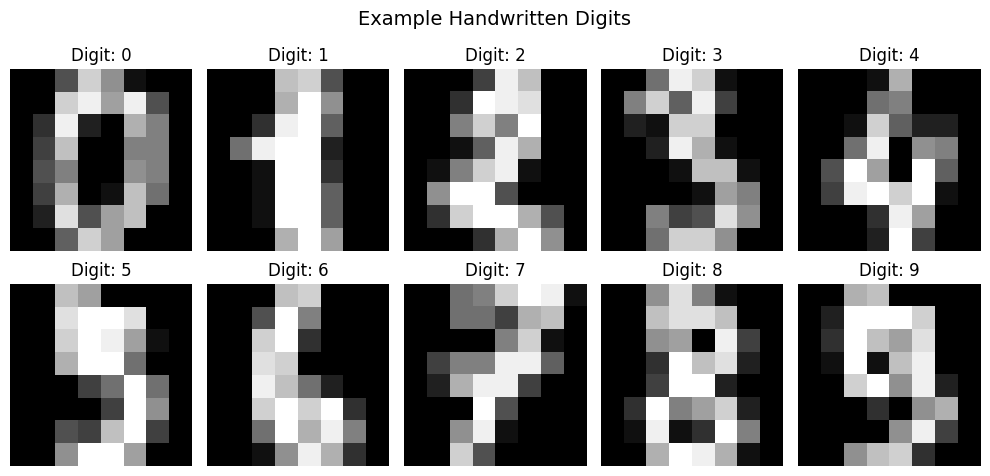

In [4]:
# ------------------------------------------------------------
# 3. Display sample images
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit, ax in zip(class_labels, axes.ravel()):
    example_index = np.flatnonzero(y == digit)[0]

    ax.imshow(
        dataset.images[example_index],
        cmap="gray",
        vmin=X.min(),
        vmax=X.max(),
        interpolation="nearest",
    )
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

fig.suptitle("Example Handwritten Digits", fontsize=14)
plt.tight_layout()

sample_plot_path = OUTPUT_DIR / "sample_digits.png"
fig.savefig(sample_plot_path, dpi=150, bbox_inches="tight")
record_file(sample_plot_path)

plt.show()
plt.close(fig)


In [5]:
# ------------------------------------------------------------
# 4. Split the data
# Keep the test set separate from model selection.
# ------------------------------------------------------------

all_indices = np.arange(len(X))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("\nTraining images:", len(X_train))
print("Test images:", len(X_test))



Training images: 1437
Test images: 360


In [6]:
# ------------------------------------------------------------
# 5. Define candidate models
# Scaling stays inside the pipeline for cross-validation.
# ------------------------------------------------------------

models = {
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    ),

    "Random forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)



In [7]:
# ------------------------------------------------------------
# 6. Compare models using only the training set
# ------------------------------------------------------------

comparison_rows = []

for model_name, candidate in models.items():
    print(f"\nCross-validating: {model_name}")

    scores = cross_validate(
        estimator=candidate,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro",
        },
        n_jobs=-1,
        error_score="raise",
    )

    comparison_rows.append({
        "model": model_name,
        "cv_accuracy": float(
            scores["test_accuracy"].mean()
        ),
        "cv_accuracy_std": float(
            scores["test_accuracy"].std(ddof=1)
        ),
        "cv_macro_f1": float(
            scores["test_macro_f1"].mean()
        ),
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("cv_accuracy", ascending=False)
    .reset_index(drop=True)
)

print("\nCross-validation results:")
print(comparison.round(4).to_string(index=False))

comparison_path = OUTPUT_DIR / "model_comparison.csv"
comparison.to_csv(comparison_path, index=False)
record_file(comparison_path)



Cross-validating: Logistic regression

Cross-validating: Random forest

Cross-validation results:
              model  cv_accuracy  cv_accuracy_std  cv_macro_f1
      Random forest       0.9763           0.0109       0.9762
Logistic regression       0.9680           0.0083       0.9679


In [8]:
# ------------------------------------------------------------
# 7. Fit the selected model
# ------------------------------------------------------------

best_model_name = comparison.iloc[0]["model"]
best_model = models[best_model_name]

print("\nSelected model:", best_model_name)

best_model.fit(X_train, y_train)



Selected model: Random forest


RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=42)

In [9]:
# ------------------------------------------------------------
# 8. Evaluate on the held-out test set
# ------------------------------------------------------------

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)

# Highest predicted class probability for each image.
confidence = probabilities.max(axis=1)

metrics = {
    "selected_model": best_model_name,
    "selection_criterion": (
        "highest mean training-set cross-validation accuracy"
    ),
    "test_accuracy": float(
        accuracy_score(y_test, predictions)
    ),
    "test_macro_f1": float(
        f1_score(y_test, predictions, average="macro")
    ),
    "training_samples": int(len(X_train)),
    "test_samples": int(len(X_test)),
}

print("\nHeld-out test results:")
print(f"Accuracy: {metrics['test_accuracy']:.4f}")
print(f"Macro F1: {metrics['test_macro_f1']:.4f}")

report = classification_report(
    y_test,
    predictions,
    labels=class_labels,
    target_names=[str(label) for label in class_labels],
    zero_division=0,
)

print("\nClassification report:")
print(report)

metrics_path = OUTPUT_DIR / "test_metrics.json"

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=2)

record_file(metrics_path)

report_path = OUTPUT_DIR / "classification_report.txt"

with open(report_path, "w") as file:
    file.write(report)

record_file(report_path)




Held-out test results:
Accuracy: 0.9639
Macro F1: 0.9634

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        36
           1       0.92      0.97      0.95        36
           2       1.00      0.97      0.99        35
           3       0.97      0.97      0.97        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.92      1.00      0.96        36
           8       0.94      0.86      0.90        35
           9       0.97      0.92      0.94        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



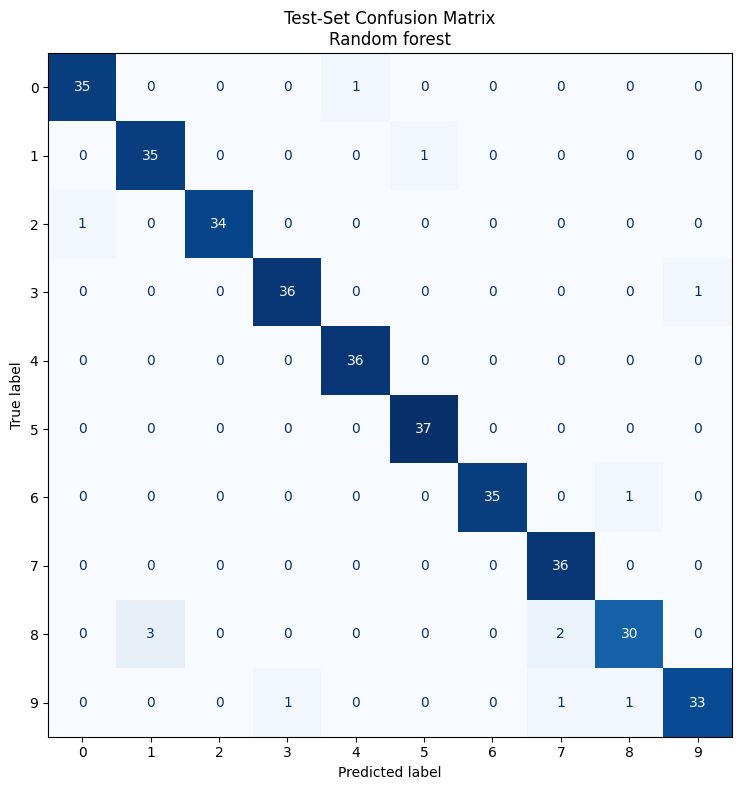

In [10]:
# ------------------------------------------------------------
# 9. Plot the confusion matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title(f"Test-Set Confusion Matrix\n{best_model_name}")
plt.tight_layout()

confusion_path = OUTPUT_DIR / "confusion_matrix.png"
fig.savefig(confusion_path, dpi=150, bbox_inches="tight")
record_file(confusion_path)

plt.show()
plt.close(fig)


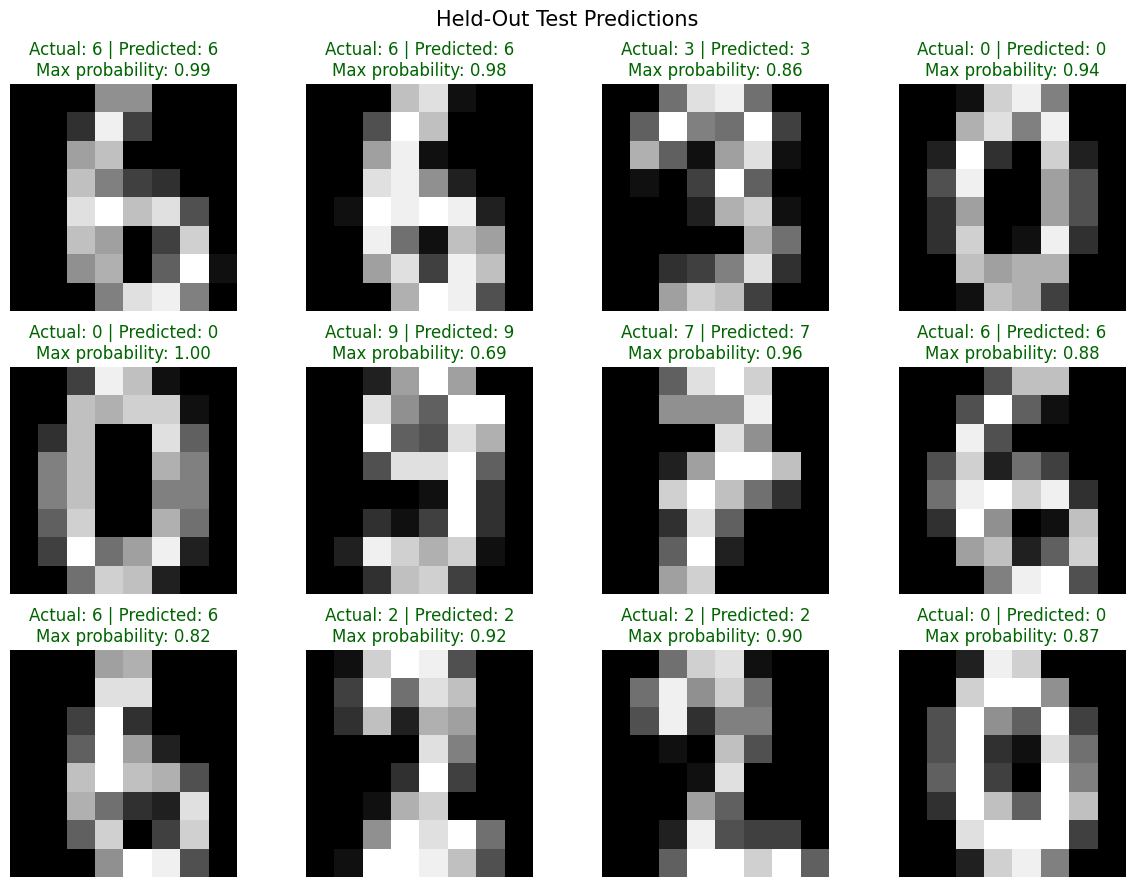

In [11]:
# ------------------------------------------------------------
# 10. Display example predictions
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_STATE)

selected_positions = rng.choice(
    len(X_test),
    size=min(12, len(X_test)),
    replace=False,
)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for position, ax in zip(
    selected_positions,
    axes.ravel(),
):
    actual = int(y_test[position])
    predicted = int(predictions[position])

    ax.imshow(
        X_test[position].reshape(image_shape),
        cmap="gray",
        vmin=X.min(),
        vmax=X.max(),
        interpolation="nearest",
    )

    title_color = (
        "darkgreen" if actual == predicted else "red"
    )

    ax.set_title(
        f"Actual: {actual} | Predicted: {predicted}\n"
        f"Max probability: {confidence[position]:.2f}",
        color=title_color,
    )
    ax.axis("off")

fig.suptitle(
    "Held-Out Test Predictions",
    fontsize=15,
)
plt.tight_layout()

predictions_plot_path = OUTPUT_DIR / "example_predictions.png"
fig.savefig(
    predictions_plot_path,
    dpi=150,
    bbox_inches="tight",
)
record_file(predictions_plot_path)

plt.show()
plt.close(fig)


Number of incorrect predictions: 13


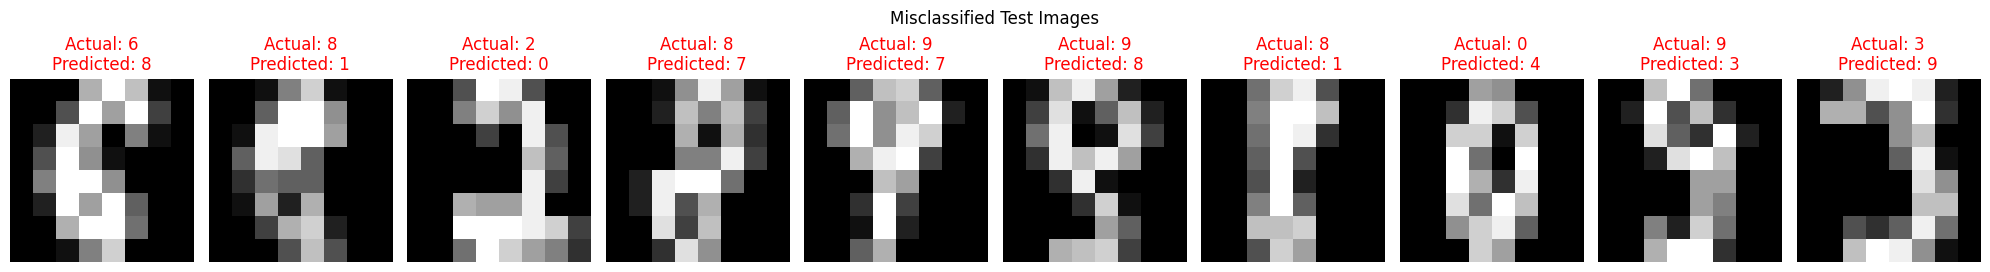

In [12]:
# ------------------------------------------------------------
# 11. Inspect misclassified images
# ------------------------------------------------------------

error_positions = np.flatnonzero(
    predictions != y_test
)

print("\nNumber of incorrect predictions:", len(error_positions))

if len(error_positions) > 0:
    number_to_show = min(10, len(error_positions))
    positions_to_show = error_positions[:number_to_show]

    fig, axes = plt.subplots(
        1,
        number_to_show,
        figsize=(2 * number_to_show, 3),
        squeeze=False,
    )

    for position, ax in zip(
        positions_to_show,
        axes.ravel(),
    ):
        ax.imshow(
            X_test[position].reshape(image_shape),
            cmap="gray",
            vmin=X.min(),
            vmax=X.max(),
            interpolation="nearest",
        )

        ax.set_title(
            f"Actual: {y_test[position]}\n"
            f"Predicted: {predictions[position]}",
            color="red",
        )
        ax.axis("off")

    fig.suptitle("Misclassified Test Images")
    plt.tight_layout()

    errors_path = OUTPUT_DIR / "misclassified_digits.png"
    fig.savefig(
        errors_path,
        dpi=150,
        bbox_inches="tight",
    )
    record_file(errors_path)

    plt.show()
    plt.close(fig)
else:
    print("No misclassified images in this test split.")


In [13]:
# ------------------------------------------------------------
# 12. Save individual test predictions
# ------------------------------------------------------------

test_results = pd.DataFrame({
    "original_image_index": test_indices,
    "actual_digit": y_test,
    "predicted_digit": predictions,
    "max_predicted_probability": confidence,
    "correct": predictions == y_test,
})

predictions_path = OUTPUT_DIR / "test_predictions.csv"
test_results.to_csv(predictions_path, index=False)
record_file(predictions_path)

In [14]:
# ------------------------------------------------------------
# 13. Save the model and metadata
# ------------------------------------------------------------

artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "dataset": "sklearn.datasets.load_digits",
    "image_shape": list(image_shape),
    "feature_count": int(X.shape[1]),
    "pixel_range": [float(X.min()), float(X.max())],
    "class_labels": class_labels.tolist(),
    "input_note": (
        "Expects flattened images in the same representation "
        "as the built-in digits dataset. External photographs "
        "require separate preprocessing and validation."
    ),
    "metrics": metrics,
    "configuration": {
        "random_state": RANDOM_STATE,
        "test_size": TEST_SIZE,
        "cv_folds": 5,
    },
    "versions": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}

model_path = OUTPUT_DIR / "digit_recognition_model.joblib"
joblib.dump(artifact, model_path)
record_file(model_path)

print("\nSaved model:", model_path)




Saved model: digit_recognition_outputs/digit_recognition_model.joblib


In [15]:
# ------------------------------------------------------------
# 14. Reload and make one prediction
# Only load model files you trust.
# ------------------------------------------------------------

loaded_artifact = joblib.load(model_path)
loaded_model = loaded_artifact["model"]

sample = X_test[[0]]

predicted_digit = int(
    loaded_model.predict(sample)[0]
)

print("\nReloaded-model example:")
print("Actual digit:", int(y_test[0]))
print("Predicted digit:", predicted_digit)



Reloaded-model example:
Actual digit: 5
Predicted digit: 5


In [16]:
# ------------------------------------------------------------
# 15. Package generated outputs
# ------------------------------------------------------------

zip_path = Path("digit_recognition_results.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for output_file in generated_files:
        archive.write(
            output_file,
            arcname=output_file.name,
        )

print("\nResults archive created:", zip_path)


Results archive created: digit_recognition_results.zip


In [17]:
# ------------------------------------------------------------
# 16. Download results in Google Colab
# ------------------------------------------------------------

try:
    from google.colab import files
except ImportError:
    print(
        "Not running in Colab. "
        "Results remain in the working directory."
    )
else:
    files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>